<a href="https://colab.research.google.com/github/jonathanxuningzhu/Deeplearning/blob/main/Multi-class%20Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import requests
from pathlib import Path

if not Path("helper_functions.py").is_file():
    response = requests.get(
        "https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py"
    )
    response.raise_for_status()
    Path("helper_functions.py").write_bytes(response.content)



Streaming output truncated to the last 5000 lines.
Epoch: 5003 | Loss: 0.63653, Acc: 71.50% | Test Loss: 0.59826, Test Acc: 76.00%
Epoch: 5004 | Loss: 0.63652, Acc: 71.50% | Test Loss: 0.59826, Test Acc: 76.00%
Epoch: 5005 | Loss: 0.63652, Acc: 71.50% | Test Loss: 0.59826, Test Acc: 76.00%
Epoch: 5006 | Loss: 0.63652, Acc: 71.50% | Test Loss: 0.59826, Test Acc: 76.00%
Epoch: 5007 | Loss: 0.63651, Acc: 71.50% | Test Loss: 0.59826, Test Acc: 76.00%
Epoch: 5008 | Loss: 0.63651, Acc: 71.50% | Test Loss: 0.59826, Test Acc: 76.00%
Epoch: 5009 | Loss: 0.63651, Acc: 71.50% | Test Loss: 0.59826, Test Acc: 76.00%
Epoch: 5010 | Loss: 0.63650, Acc: 71.50% | Test Loss: 0.59825, Test Acc: 76.00%
Epoch: 5011 | Loss: 0.63650, Acc: 71.50% | Test Loss: 0.59825, Test Acc: 76.00%
Epoch: 5012 | Loss: 0.63649, Acc: 71.50% | Test Loss: 0.59825, Test Acc: 76.00%
Epoch: 5013 | Loss: 0.63649, Acc: 71.50% | Test Loss: 0.59825, Test Acc: 76.00%
Epoch: 5014 | Loss: 0.63649, Acc: 71.50% | Test Loss: 0.59825, Test A

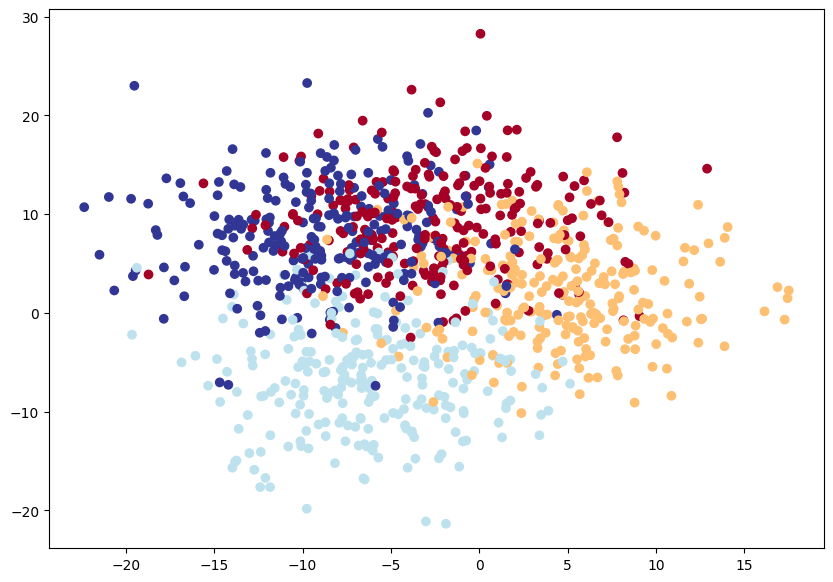

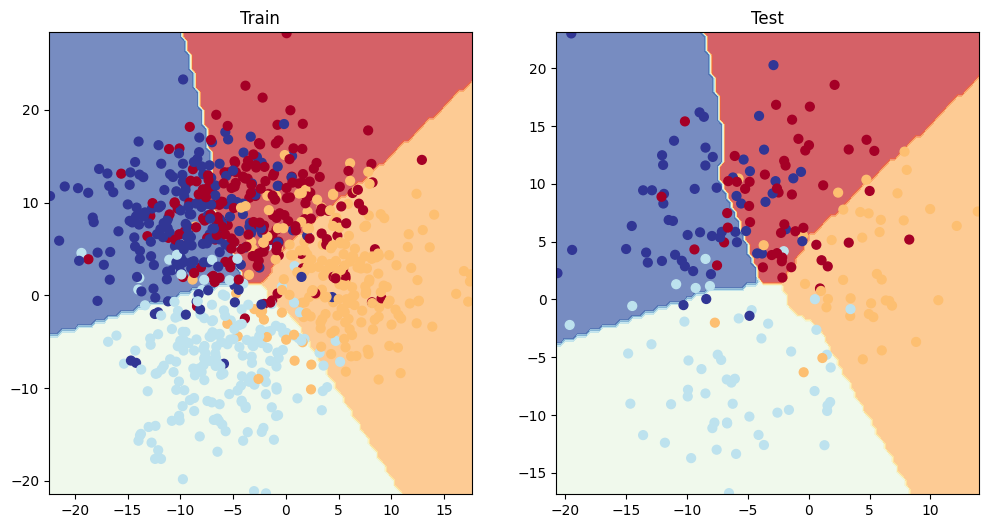

In [ ]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from helper_functions import plot_decision_boundary

NUM_CLASSES = 4
NUM_FEATURES = 2
RANDOM_SEED = 42

def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc


device = "cuda" if torch.cuda.is_available() else "cpu"
X_blob, y_blob = make_blobs(
    n_samples=1000,
    n_features=NUM_FEATURES,
    centers=NUM_CLASSES,
    cluster_std=5,
    random_state=RANDOM_SEED
)

X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)
print(X_blob[:5], y_blob[:5])

X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(
    X_blob,
    y_blob,
    test_size=0.2,
    random_state=RANDOM_SEED
)

plt.figure(figsize=(10, 7))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap=plt.cm.RdYlBu);

from torch import nn




class BlobModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer_1 = nn.Linear(2, 10)
        self.layer_2 = nn.Linear(10, 100)
        self.layer_3 = nn.Linear(100,4 )
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

model_4 = BlobModel().to(device)

model_4


loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_4.parameters(),
                            lr=0.002)


y_logits = model_4(X_blob_test.to(device))


y_pred_probs = torch.softmax(y_logits, dim=1)
print(y_logits[:5])
print(y_pred_probs[:5])


torch.sum(y_pred_probs[0])


print(y_pred_probs[0])
print(torch.argmax(y_pred_probs[0]))



torch.manual_seed(42)


epochs = 10000


X_blob_train, y_blob_train = X_blob_train.to(device), y_blob_train.to(device)
X_blob_test, y_blob_test = X_blob_test.to(device), y_blob_test.to(device)

for epoch in range(epochs):

    model_4.train()


    y_logits = model_4(X_blob_train)
    y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)


    loss = loss_fn(y_logits, y_blob_train)
    acc = accuracy_fn(y_true=y_blob_train,
                      y_pred=y_pred)


    optimizer.zero_grad()


    loss.backward()


    optimizer.step()


    model_4.eval()
    with torch.inference_mode():

      test_logits = model_4(X_blob_test)
      test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)

      test_loss = loss_fn(test_logits, y_blob_test)
      test_acc = accuracy_fn(y_true=y_blob_test,
                             y_pred=test_pred)



      print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")

model_4.eval()
with torch.inference_mode():
    y_logits = model_4(X_blob_test)


y_pred_probs = torch.softmax(y_logits, dim=1)


y_preds = y_pred_probs.argmax(dim=1)


print(f"Predictions: {y_preds[:10]}\nLabels: {y_blob_test[:10]}")
print(f"Test accuracy: {accuracy_fn(y_true=y_blob_test, y_pred=y_preds)}%")


plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_4, X_blob_train, y_blob_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_4, X_blob_test, y_blob_test)